In [29]:
# Add this code to a new cell in the notebook


import scanpy as sc
import pandas as pd
import os
import numpy as np
from scipy.stats import pearsonr

import matplotlib.pyplot as plt


In [2]:
# --- Global font settings (consistent, larger, bold titles) ---
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "legend.title_fontsize": 16,
    "figure.titlesize": 22,
    "figure.titleweight": "bold",
})


In [3]:
# import scipy.io
# barcodes_file = "GSE213753_RAW/GSM6593509_barcodes.tsv.gz"
# genes_file = "GSE213753_RAW/GSM6593509_genes.tsv.gz"
# matrix_file = "GSE213753_RAW/GSM6593509_matrix.mtx.gz"
# annotation_file = "GSE213753_RAW/GSM6593509_Concentration_GBC_annotation_Samples.csv.gz"
#
# # Load matrix (gene expression) and convert to CSR format for efficient indexing
# X = scipy.io.mmread(matrix_file).T.tocsr()  # Convert to CSR to allow indexing
#
# # Load barcodes (cell IDs)
# barcodes = pd.read_csv(barcodes_file, header=None)[0].values
#
# # Load genes (gene names)
# genes = pd.read_csv(genes_file, header=None)[0].values
#
# # Create AnnData object
# adata = sc.AnnData(X)
# adata.var_names = genes  # Gene names
# adata.obs_names = barcodes  # Cell barcodes
#
# # Load sample annotation
# obs_metadata = pd.read_csv(annotation_file, index_col=0)
#
# # Retain only cells that have metadata available
# valid_barcodes = adata.obs_names.isin(obs_metadata.index)
# adata = adata[valid_barcodes].copy()  # Now this works!
#
# # Subset metadata to match retained cells
# adata.obs = obs_metadata.loc[adata.obs_names]
#
# # Save as h5ad (optional)
# # adata.write("GSM6593509.h5ad")
#
# # Check the object
# print(adata)

In [4]:
# GT_CLUSTER_LABEL = "dose_pM"
# LINEAR_LABEL = "76GS_EMT_score"
# N_TOP_GENES = 12000
# adata.X = adata.X.toarray().astype('float32')
#
# if np.any(np.isnan(adata.X)) or np.any(np.isinf(adata.X)):
#     print("Data contains NaN or infinite values!")
#
# # Split the 'var_names' by the tab character and keep only the gene names
# adata.var_names = adata.var_names.str.split('\t').str[1]
#
# # Verify the updated 'var_names'
# print(adata.var_names[:10])  # Check the first 10 gene names
#
# # Define the mapping for 'GBC_annot' to 'dose_pM'
# dose_mapping = {
#     'GBC1': 0,
#     'GBC2': 12.5,
#     'GBC3': 25,
#     'GBC4': 50,
#     'GBC8': 100,
#     'GBC9': 200,
#     'GBC12': 400,
#     'GBC13': 800
# }
#
# # Apply the mapping to create the 'dose_pM' column
# adata.obs['dose_pM'] = adata.obs['GBC_annot'].map(dose_mapping)
#
# # Check the updated 'dose_pM' column
# print(adata.obs[['GBC_annot', 'dose_pM']].head())
#
# sc.pp.filter_genes_dispersion(adata, n_top_genes=N_TOP_GENES)
# sc.pp.normalize_total(adata)
# sc.pp.log1p(adata)
#
# adata = adata[:, ~adata.var_names.duplicated()].copy()  # Keep only unique genes
# adata.var_names = adata.var_names.str.strip()
#
#


In [5]:
# List of 76 genes (updated and deduplicated)
emt_76gs_genes = [
    "ZEB1", "LIX1L", "VIM", "AXL", "MMP2", "ANTXR2", "C3ORF21", "FN1", "NRP1", "TGFBI",
    "GALNT5", "PPARG", "HNMT", "CARD6", "RBPMS", "TNFRSF21", "TMEM45B", "MPP7", "SSH3",
    "MTAC2D1", "MUC1", "EPPK1", "SHROOM3", "EPN3", "PRSS22", "AP1M2", "SH3YL1", "KLC3",
    "SERINC2", "EVPL", "FXYD3", "CLDN4", "CRB3", "LRRC54", "MAPK13", "GALNT3", "STAP2",
    "DSP", "ELMO3", "KRTCAP3", "MAL2", "FL1R", "GPR110", "GPR56", "KRT19", "GRHL1",
    "BSPRY", "CLORF116", "S100A14", "SPINT2", "ANKRD22", "ST14", "GRHL2", "PRR5", "TJP3",
    "TACSTD2", "CDH3", "CLORF172", "CDS1", "MPZL2", "INADL", "RBM35A", "TMC4", "ITGB6",
    "TMEM125", "EPHA1", "ENPP5", "EPB41L5", "ERBB3", "RAB25", "PRSS8", "TMEM30B",
    "CLDN7", "SCNN1A", "CDH1"
]

def EMT76GS(adata, outDir=None, gseID="EMT76GS"):
    """
    Compute EMT scores using the 76-gene signature (76GS) method on an AnnData object.

    Parameters:
        adata (AnnData): Anndata object containing gene expression data.
        outDir (str, optional): Directory to save the output file.
        gseID (str, optional): Identifier for the dataset.

    Returns:
        np.array: EMT scores for all cells.
    """
    print("Calculating EMT Score using 76 gene signatures...")

    # Ensure gene names are formatted consistently
    adata.var_names = adata.var_names.str.strip().str.upper()

    # Filter existing genes from the 76-gene signature
    existing_genes = [g for g in emt_76gs_genes if g in adata.var_names]

    # If no matching genes, return zero scores
    if len(existing_genes) == 0:
        print("No 76GS genes found in dataset. Returning zeros.")
        adata.obs["76GS_EMT_score"] = 0
        return np.zeros(adata.shape[0])

    print(f"{len(existing_genes)} out of 76 genes found in dataset.")

    # Copy adata to bdata and retain only the existing genes
    bdata = adata[:, existing_genes].copy()

    # Extract expression matrix for matched genes
    #EMTMat = bdata.X.toarray() if isinstance(bdata.X, np.ndarray) else bdata.X
    EMTMat = bdata.X
    # Replace NaN with zero
    EMTMat[np.isnan(EMTMat)] = 0

    # Find CDH1 index for weighting
    if "CDH1" not in existing_genes:
        print("CDH1 gene not found - 76GS EMT score cannot be calculated.")
        EMTScoreStd = np.zeros(adata.shape[0])
    else:
        ecadh_exp_idx = existing_genes.index("CDH1")
        ecadh_exp_val = EMTMat[:, ecadh_exp_idx]

        # Compute correlation weights for each gene with CDH1
        weight_vals = np.array([
            pearsonr(EMTMat[:, i], ecadh_exp_val)[0] if not np.all(EMTMat[:, i] == ecadh_exp_val) else 0
            for i in range(EMTMat.shape[1])
        ])

        # Fix: Multiply weights by the expression matrix
        # Here, we need to multiply weights across genes (per gene, per cell)
        EMTMatWt = EMTMat * weight_vals  # Broadcasting across cells

        # Compute weighted EMT scores per cell (sum across genes)
        EMTScore = np.sum(EMTMatWt, axis=1)

        # Normalize EMT scores
        EMTScoreMean = np.mean(EMTScore)
        EMTScoreStd = EMTScore - EMTScoreMean

    # Store results in adata (per cell)
    adata.obs["76GS_EMT_score"] = EMTScoreStd

    # Save results if outDir is provided
    # if outDir:
    #    outFile = f"{outDir}/{gseID}_EMT_76GS.txt"
    #    pd.DataFrame({"Sample": adata.obs_names, "76GS_EMT_Score": EMTScoreStd}).to_csv(outFile, sep="\t", index=False)

    return EMTScoreStd
# res = EMT76GS(adata, outDir="./results", gseID="GSE12345")

Start here

In [6]:
# Replace the existing code in the cell with this updated version to handle all relevant files and add new labels

import pandas as pd
import numpy as np
from scipy.stats import pearsonr

import matplotlib.pyplot as plt
import os
import scanpy as sc



def circ_distance(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2*np.pi - diff)


def affinity(a, b, sigma):
    d = circ_distance(a, b)
    return np.exp(-(d**2) / (2*sigma**2))

print(os.getcwd())
# Directory path
directory = 'EMT_CC_data'

# List files in the directory (including .h5ad, .csv, .tsv, .txt)
files = [f for f in os.listdir(directory) if f.endswith(('.csv', '.tsv', '.txt', '.h5ad'))]
print(f"Found files: {files}")

# Dictionary to hold AnnData objects
adata_dict = {}

for file in files:
    file_path = os.path.join(directory, file)

    # if file.endswith('.h5ad'):
        # Load existing AnnData from .h5ad file
    adata = sc.read_h5ad(file_path)


    vector_phase = adata.obs['assigned_phase']

    unique_phases = sorted(adata.obs['assigned_phase'].unique())
    n_phases = len(unique_phases)
    angles_phases = np.linspace(0, 2 * np.pi, n_phases, endpoint=False)
    phase_to_angle = dict(zip(unique_phases, angles_phases))
    adata.obs['phase_vector'] = adata.obs['assigned_phase'].map(phase_to_angle)

    cell_angles = np.array(adata.obs['phase_vector'])  # angles in radians
    affinity_vectors = []
    print(unique_phases)
    for phase in unique_phases:
        phase_angle = phase_to_angle[phase]
        print(phase, phase_angle)
        deltas = np.abs(cell_angles - phase_angle)
        deltas = np.minimum(deltas, 2 * np.pi - deltas)
        print(deltas.shape)
        affinities = np.exp(-deltas / np.pi)
        affinity_vectors.append(affinities)

    #map phases to angles
    # phases = ["G1.S", "G2", "G2.M", "M.G1", "S"]
    # angles = [(k * np.pi) / 3 for k in range(1, 6)]
    # phase_to_angle = dict(zip(phases, angles))
    # n = len(phases)
    # A = np.zeros((n, n))
    # sigma = 0.8
    # for i, p1 in enumerate(phases):
    #     for j, p2 in enumerate(phases):
    #         A[i, j] = affinity(phase_to_angle[p1], phase_to_angle[p2], sigma)
    print(len(affinity_vectors))

    aff = np.array(affinity_vectors)  # shape (5, 610)
    print(aff.shape)
    #transform that to a list of 610 elements where each element is a list of 5 affinities
    aff = aff.T  # shape (610, 5)
    #transform to list of lists

    adata.obs['phase_affinity_list'] = list(aff)
    adata.obsm['phase_affinity'] = aff
    print(adata.obsm['phase_affinity'].shape)
    if '76GS_EMT_score' in adata.obs.columns:
        min_score = adata.obs['76GS_EMT_score'].min()
        max_score = adata.obs['76GS_EMT_score'].max()
        adata.obs['EMT_score_normalized'] = (adata.obs['76GS_EMT_score'] - min_score) / (max_score - min_score)

    # Store in dictionary with filename as key
    adata_dict[file] = adata

    print(f"Loaded/Created AnnData for {file} and added new labels")

# Now you can access adata_dict['filename'] for each AnnData object

/cs/labs/mornitzan/jeremies/processes_interactions/GSP2
Found files: ['adata_dose_by_phase_25p0.h5ad', 'adata_dose_by_phase_400p0.h5ad', 'adata_dose_by_phase_100p0.h5ad', 'adata_dose_by_phase_200p0.h5ad', 'adata_dose_by_phase_800p0.h5ad', 'adata_dose_by_phase_0p0.h5ad', 'adata_dose_by_phase_12p5.h5ad', 'adata_dose_by_phase_50p0.h5ad']
['G1.S', 'G2', 'G2.M', 'M.G1', 'S']
G1.S 0.0
(610,)
G2 1.2566370614359172
(610,)
G2.M 2.5132741228718345
(610,)
M.G1 3.7699111843077517
(610,)
S 5.026548245743669
(610,)
5
(5, 610)
(610, 5)
Loaded/Created AnnData for adata_dose_by_phase_25p0.h5ad and added new labels
['G1.S', 'G2', 'G2.M', 'M.G1', 'S']
G1.S 0.0
(556,)
G2 1.2566370614359172
(556,)
G2.M 2.5132741228718345
(556,)
M.G1 3.7699111843077517
(556,)
S 5.026548245743669
(556,)
5
(5, 556)
(556, 5)
Loaded/Created AnnData for adata_dose_by_phase_400p0.h5ad and added new labels
['G1.S', 'G2', 'G2.M', 'M.G1', 'S']
G1.S 0.0
(748,)
G2 1.2566370614359172
(748,)
G2.M 2.5132741228718345
(748,)
M.G1 3.7699111

In [7]:
import anndata as ad
import matplotlib.cm as cm
import matplotlib.colors as mcolors

adata_combined = ad.concat(
    adata_dict,
    axis=0,
    join="outer",
    label="dataset",
    fill_value=0
)
adata_combined.obs["dose_pM"] = adata_combined.obs["dose_pM"].astype(float)

# ordered categorical dose with viridis gradient — each dose gets a named legend entry
doses_ordered = sorted(adata_combined.obs["dose_pM"].dropna().unique())
dose_labels = [str(int(d)) if d == int(d) else str(d) for d in doses_ordered]
adata_combined.obs["dose_pM_cat"] = (
    adata_combined.obs["dose_pM"]
    .map(dict(zip(doses_ordered, dose_labels)))
    .astype("category")
)
adata_combined.obs["dose_pM_cat"] = adata_combined.obs["dose_pM_cat"].cat.set_categories(
    dose_labels, ordered=True
)
_cmap = cm.get_cmap("viridis", len(doses_ordered))
adata_combined.uns["dose_pM_cat_colors"] = [
    mcolors.to_hex(_cmap(i / (len(doses_ordered) - 1))) for i in range(len(doses_ordered))
]

print(adata_combined.obs)

                   GBC_annot  Values  dose_pM   S_score  G2M_score phase  \
AAACCTGGTCCAAGTT-1      GBC3       3     25.0  0.247635   0.185071     S   
AAACGGGGTCTAAAGA-1      GBC3       3     25.0 -0.017631   0.414669   G2M   
AAAGTAGCAGTCGTGC-1      GBC3       3     25.0 -0.165351  -0.242598    G1   
AAAGTAGGTGGCGAAT-1      GBC3       3     25.0  0.037155   0.362472   G2M   
AAAGTAGTCACATAGC-1      GBC3       3     25.0 -0.061982  -0.140851    G1   
...                      ...     ...      ...       ...        ...   ...   
TTTCCTCGTTCGTTGA-1      GBC4       4     50.0 -0.154578  -0.257045    G1   
TTTGGTTAGCGATAGC-1      GBC4       4     50.0  0.028744   0.429779   G2M   
TTTGTCACAGCTGGCT-1      GBC4       4     50.0 -0.072703  -0.198121    G1   
TTTGTCACATTGTGCA-1      GBC4       4     50.0 -0.123159  -0.217691    G1   
TTTGTCAGTAAGTGGC-1      GBC4       4     50.0 -0.165657  -0.282754    G1   

                    76GS_EMT_score assigned_phase phase_vector  \
AAACCTGGTCCAAGTT-1   

/tmp/ipykernel_3960789/1055944773.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap = cm.get_cmap("viridis", len(doses_ordered))


In [8]:
try:
    from sift import SiFT
except ImportError:
    from sift._sift import SiFT

from scipy.spatial.distance import pdist


def plot_sift_kernel(
    adata,
    signal_key,
    groupby,
    n_neighbors=15,
    metric="knn",
    kernel_params=None,
    figsize=(7, 6),
    cmap="Blues",
    ax=None,
    save_path=None,
):
    bdata = adata.copy()
    kparams = dict(kernel_params or {})
    median_factor = kparams.pop("median_factor", 0.5)

    try:
        sort_idx = np.argsort(bdata.obs[groupby].values.astype(float))
    except (ValueError, TypeError):
        sort_idx = np.argsort(bdata.obs[groupby].astype(str).values)
    bdata = bdata[sort_idx].copy()

    # Median heuristic for RBF bandwidth
    if metric != "knn" and "length_scale" not in kparams:
        signal = bdata.obsm[signal_key]
        if hasattr(signal, "toarray"):
            signal = signal.toarray()
        dists = pdist(np.array(signal, dtype=float))
        dists = dists[dists > 0]
        kparams["length_scale"] = median_factor * (float(np.median(dists)) if len(dists) > 0 else 1.0)
        print(f"[plot_sift_kernel] RBF length_scale (median * {median_factor}): {kparams['length_scale']:.6f}")

    sft = SiFT(bdata, kernel_key=signal_key, metric=metric, n_neighbors=n_neighbors, kernel_params=kparams)

    if metric == "knn":
        raw_k = sft._kernel(**sft._kernel_containers)
        K = raw_k.toarray() if hasattr(raw_k, "toarray") else np.array(raw_k)
    else:
        raw_k = sft._kernel(materialize=True, **sft._kernel_containers)
        K = raw_k.cpu().numpy() if hasattr(raw_k, "cpu") else np.array(raw_k)

    K = K.astype(float)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(K, cmap=cmap, aspect="auto", interpolation="none", vmin=0)
    plt.colorbar(im, ax=ax, shrink=0.8, label="Kernel weight")

    labels = bdata.obs[groupby].values
    try:
        labels = labels.astype(float)
    except (ValueError, TypeError):
        pass
    unique_labels, counts = np.unique(labels, return_counts=True)
    midpoints = np.cumsum(counts) - counts / 2
    boundaries = np.cumsum(counts)[:-1]

    for b in boundaries:
        ax.axvline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)
        ax.axhline(b - 0.5, color="red", linewidth=0.8, alpha=0.5)

    ax.set_xticks(midpoints)
    ax.set_xticklabels(unique_labels, rotation=45, ha="right", fontsize=14)
    ax.set_yticks(midpoints)
    ax.set_yticklabels(unique_labels, fontsize=14)
    ax.set_title(
        f"SIFT kernel  |  signal: '{signal_key}' ({metric})\nsorted by '{groupby}'  "
        f"(n={bdata.n_obs})",
        fontsize=20,
    )

    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=150)
    plt.tight_layout()
    return ax

In [9]:
import crisp

print(adata_combined.obs["dose_pM"].unique())


crisp.encode_obs(adata_combined, "76GS_EMT_score")
crisp.encode_obs(adata_combined, "dose_pM")

print(adata_combined.obs["dose_pM"].unique())
# def add_modified_dose(adata):
#     dose_map = {0: 0, 12.5: 1, 25: 2, 50: 3, 100: 4, 200: 5, 400: 6, 800: 7}
#     adata.obs["dose_pM"] = adata.obs["dose_pM"].map(dose_map).astype(int)
#     return adata
#
# adata_combined = add_modified_dose()

[ 25.  400.  100.  200.  800.    0.   12.5  50. ]
[ 25.  400.  100.  200.  800.    0.   12.5  50. ]


[timing] PCA + neighbors:   9.32s
[timing] SIFT signal A:     0.98s
[crisp] RBF length_scale for 'dose_pM' (median * 0.5): 0.003941
0.003940811496891655
[timing] SIFT signal B:     2.00s


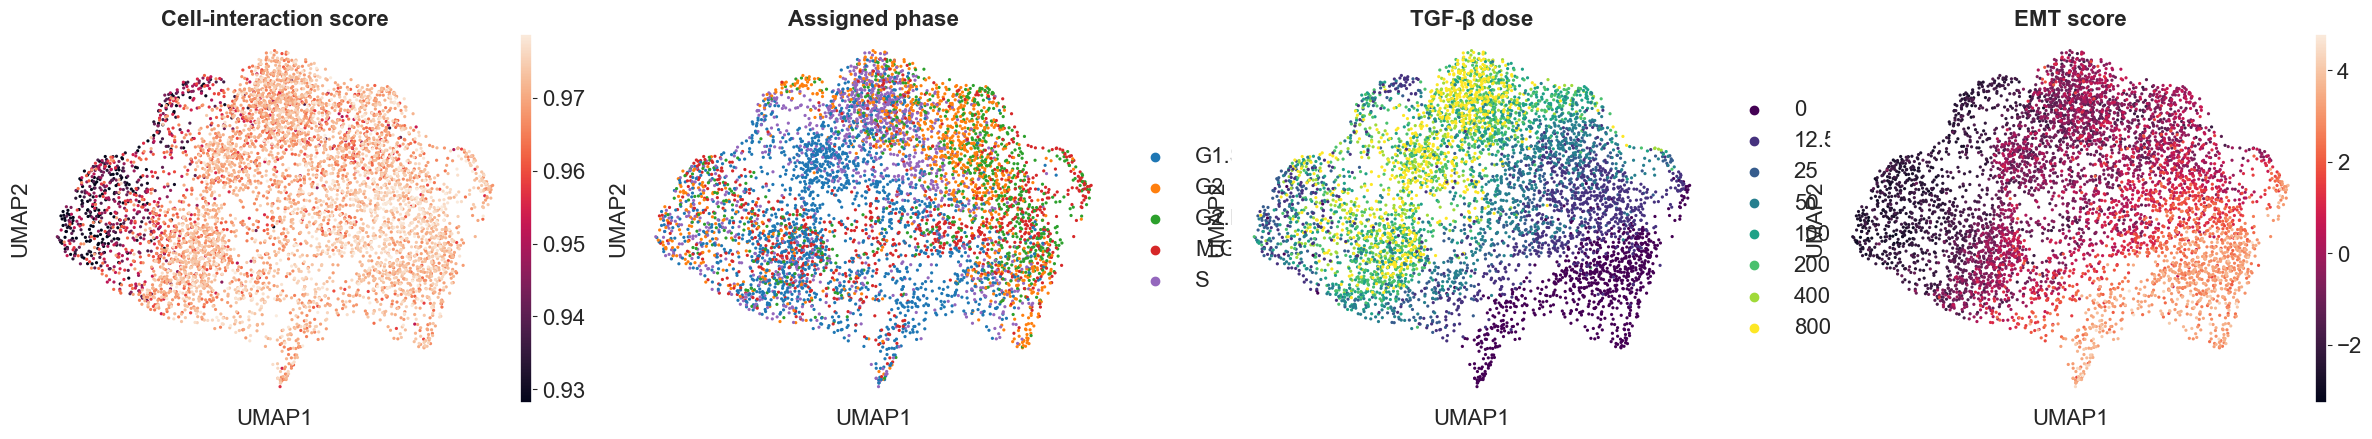

In [10]:
LENGTH_SCALE_B = None  # set to a float to override the median heuristic for dose_pM

global_score = crisp.compute_projection_similarity(
    adata_combined,
    signal_A="76GS_EMT_score",
    signal_B="dose_pM",
    embedding_key="X",
    metric_A="knn",
    metric_B="rbf",
    device="cuda",
    kernel_params_B={"length_scale": LENGTH_SCALE_B} if LENGTH_SCALE_B is not None else None,
)

cell_score = "proj_pearson_cell"
sc.pp.neighbors(adata_combined, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata_combined)
score = adata_combined.obs[cell_score]
low_thr = score.quantile(0.025)
high_thr = score.quantile(0.975)
sc.pl.umap(
    adata_combined,
    color=[cell_score, "assigned_phase", "dose_pM_cat", "76GS_EMT_score"],
    title=["Cell-interaction score", "Assigned phase", "TGF-β dose", "EMT score"],
    vmin=[low_thr, None, None, None],
    vmax=[high_thr, None, None, None],
)

[plot_sift_kernel] RBF length_scale (median * 0.5): 0.003941


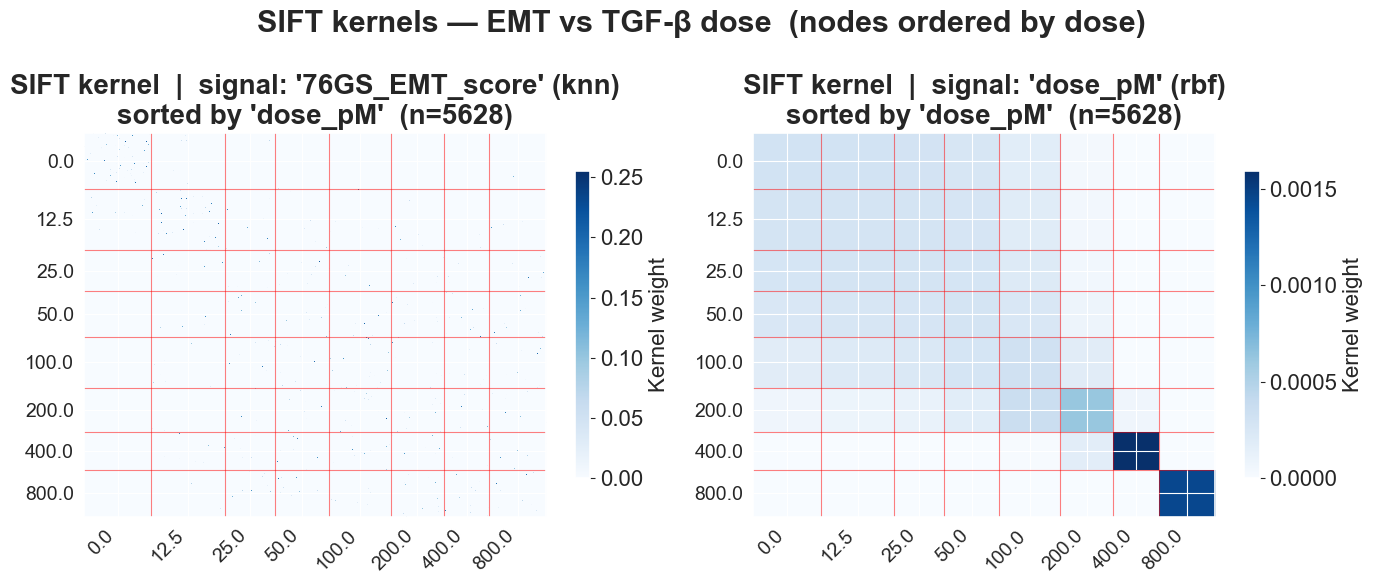

In [11]:
# Setting 1: EMT vs TGF-β dose — kernels sorted by dose_pM
LENGTH_SCALE_B = None
_outdir1 = "../EMT-TGFBeta_figures_pearson_rbf"
os.makedirs(_outdir1, exist_ok=True)
_kp = {"length_scale": LENGTH_SCALE_B} if LENGTH_SCALE_B is not None else None
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_sift_kernel(
    adata_combined,
    signal_key="76GS_EMT_score",
    groupby="dose_pM",
    metric="knn",
    ax=axes[0],
)
plot_sift_kernel(
    adata_combined,
    signal_key="dose_pM",
    groupby="dose_pM",
    kernel_params=_kp,
    metric="rbf",
    ax=axes[1],
)
plt.suptitle("SIFT kernels — EMT vs TGF-β dose  (nodes ordered by dose)", fontsize=22)
plt.tight_layout()
plt.savefig(os.path.join(_outdir1, "kernels_emt_vs_dose.png"), bbox_inches="tight", dpi=150)
plt.show()

/tmp/ipykernel_3960789/545836250.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_cool = cm.get_cmap("cool", _n)


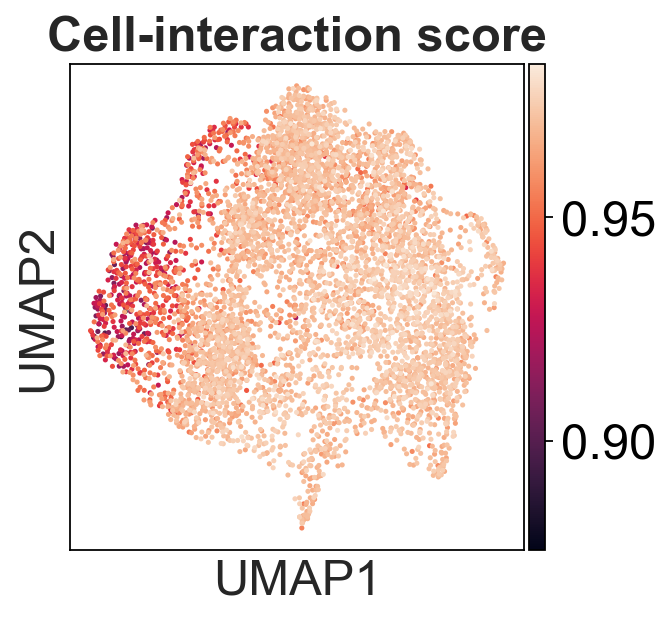

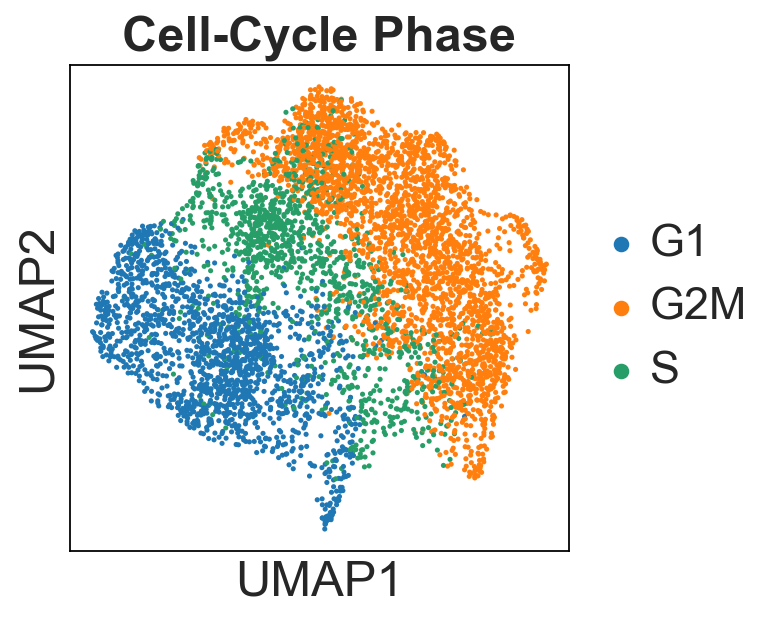

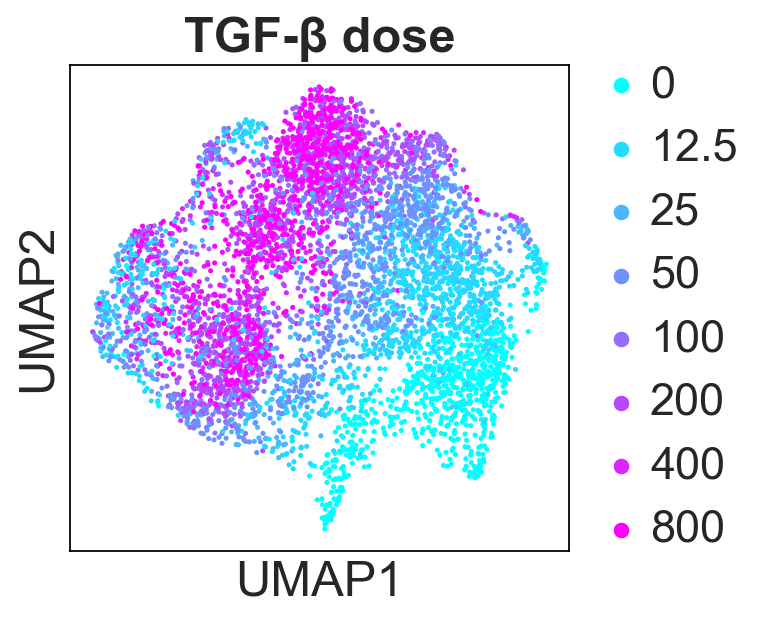

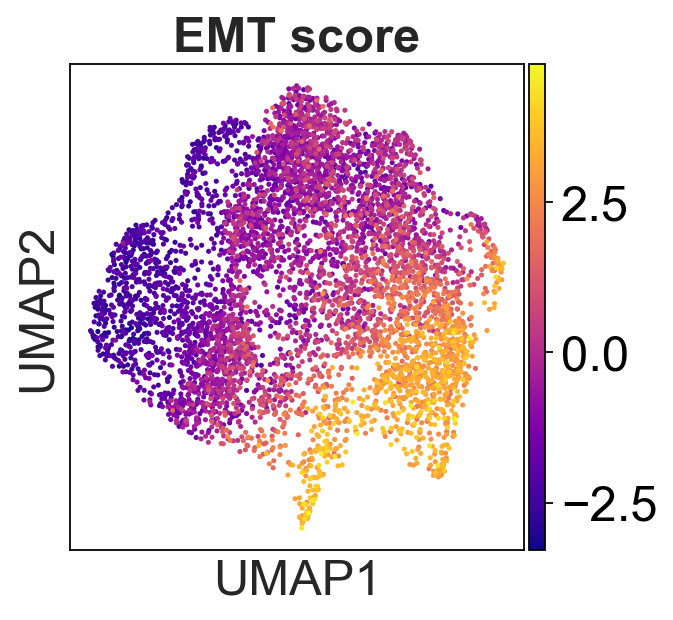

In [12]:
outdir = "../EMT-TGFBeta_figures_pearson_rbf"
os.makedirs(outdir, exist_ok=True)
sc.settings.figdir = outdir
sc.settings.set_figure_params(fontsize=22)
cell_score = "proj_pearson_cell"
sc.pp.neighbors(adata_combined, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata_combined)
score = adata_combined.obs[cell_score]

# update dose colors to "cool"
_doses_cat = adata_combined.obs["dose_pM_cat"].cat.categories
_n = len(_doses_cat)
_cmap_cool = cm.get_cmap("cool", _n)
adata_combined.uns["dose_pM_cat_colors"] = [
    mcolors.to_hex(_cmap_cool(i / max(_n - 1, 1))) for i in range(_n)
]

for _color, _save, _title, _kwargs in [
    (cell_score,       "_emt_tgf_cell_score.png", "Cell-interaction score",  {}),
    ("phase",          "_emt_tgf_phase.png",       "Cell-Cycle Phase",       {}),
    ("dose_pM_cat",    "_emt_tgf_dose.png",        "TGF-β dose",  {}),
    ("76GS_EMT_score", "_emt_tgf_emt_score.png",   "EMT score",   {"color_map": "plasma"}),
]:
    sc.pl.umap(adata_combined, color=[_color], title=[_title], save=_save, **_kwargs)

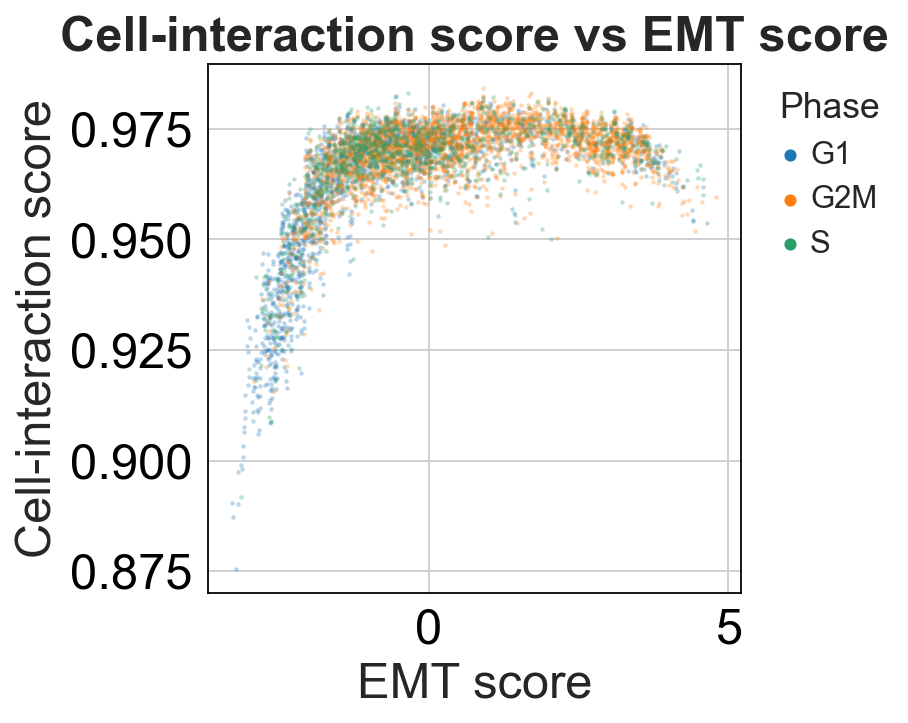

In [13]:
from scipy.stats import spearmanr

x = adata_combined.obs["76GS_EMT_score"]
y = adata_combined.obs[cell_score]
r, p = spearmanr(x, y)

phases = adata_combined.obs["phase"].cat.categories
phase_colors = dict(zip(phases, adata_combined.uns["phase_colors"]))

fig, ax = plt.subplots(figsize=(6, 5))
for phase in phases:
    mask = adata_combined.obs["phase"] == phase
    ax.scatter(x[mask], y[mask], color=phase_colors[phase],
               s=4, alpha=0.3, linewidths=0, rasterized=True, label=phase)

handles = [plt.scatter([], [], color=phase_colors[p], s=20, label=p) for p in phases]
ax.legend(handles=handles, title="Phase", bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=14, title_fontsize=16, frameon=False)
ax.set_xlabel("EMT score")
ax.set_ylabel("Cell-interaction score")
ax.set_title(f"Cell-interaction score vs EMT score")

plt.tight_layout()
fig.savefig(os.path.join(outdir, "spearman_cell_vs_emt_score_phase_colored.png"), dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_3960789/725666466.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_cool = cm.get_cmap("cool", _n)


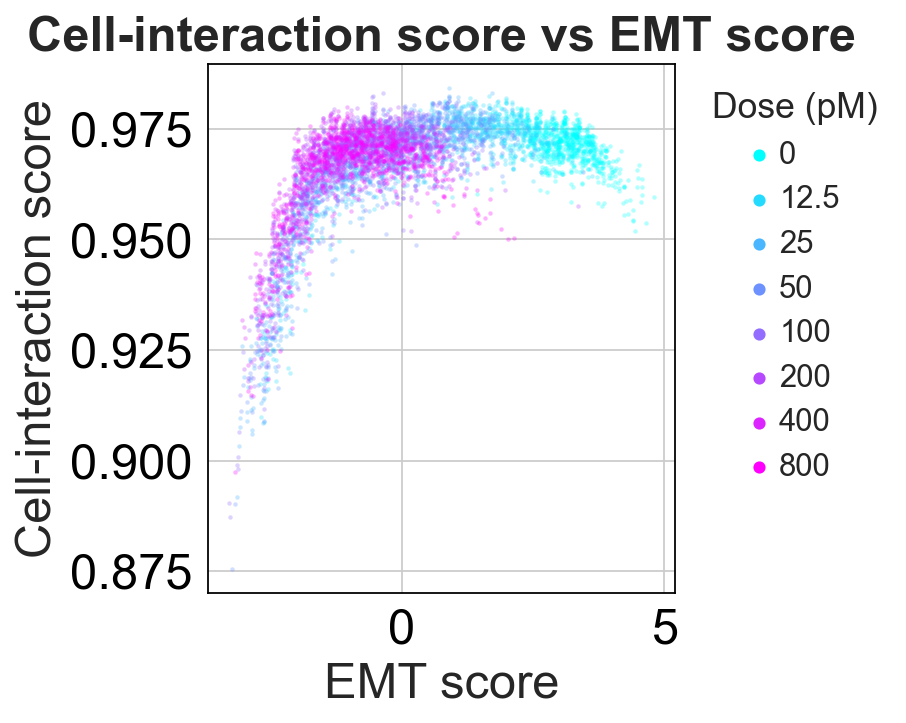

In [14]:
doses = adata_combined.obs["dose_pM_cat"].cat.categories
_n = len(doses)
_cmap_cool = cm.get_cmap("cool", _n)
dose_colors = {d: mcolors.to_hex(_cmap_cool(i / max(_n - 1, 1))) for i, d in enumerate(doses)}

fig, ax = plt.subplots(figsize=(6, 5))
for dose in doses:
    mask = adata_combined.obs["dose_pM_cat"] == dose
    ax.scatter(x[mask], y[mask], color=dose_colors[dose],
               s=4, alpha=0.3, linewidths=0, rasterized=True, label=dose)

handles = [plt.scatter([], [], color=dose_colors[d], s=20, label=d) for d in doses]
ax.legend(handles=handles, title="Dose (pM)", bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=14, title_fontsize=16, frameon=False)
ax.set_xlabel("EMT score")
ax.set_ylabel("Cell-interaction score")
ax.set_title(f"Cell-interaction score vs EMT score")

plt.tight_layout()
fig.savefig(os.path.join(outdir, "spearman_cell_vs_emt_score_dose_colored.png"), dpi=300, bbox_inches="tight")
plt.show()


/tmp/ipykernel_3960789/4030880044.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = {d: plt.cm.get_cmap("cool")(i / (n - 1)) for i, d in enumerate(dose_order)}


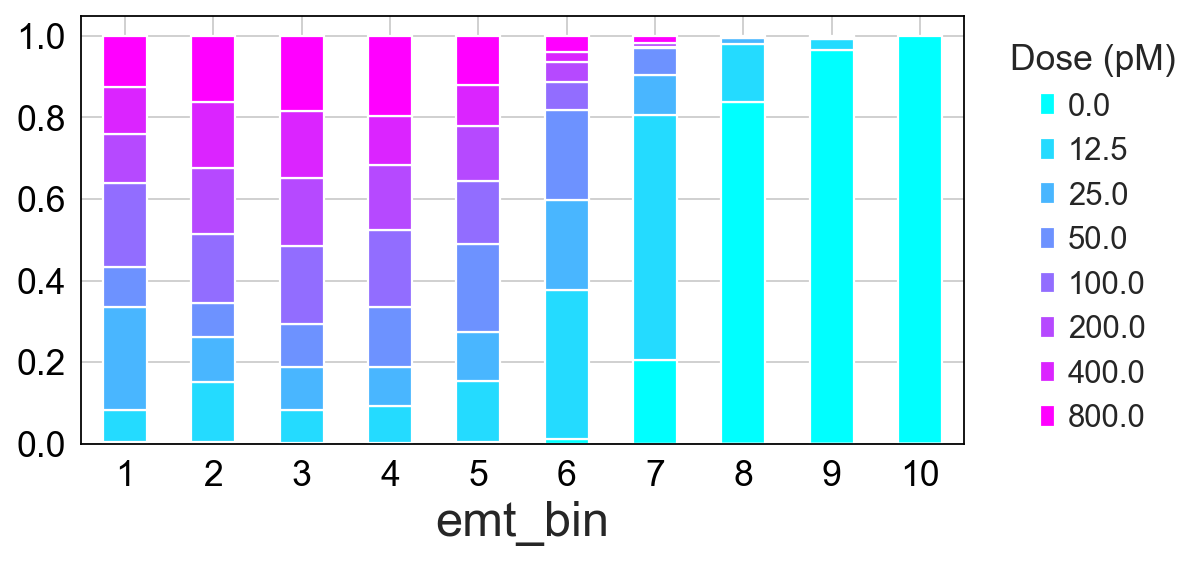

In [34]:
dose_order = sorted(adata_combined.obs["dose_pM"].unique())
n = len(dose_order)
palette = {d: plt.cm.get_cmap("cool")(i / (n - 1)) for i, d in enumerate(dose_order)}

obs = adata_combined.obs.copy()
obs["emt_bin"] = pd.cut(obs["76GS_EMT_score"], bins=10)

dist = pd.crosstab(obs["emt_bin"], obs["dose_pM"], normalize="index")
dist = dist[dose_order]


fig, ax = plt.subplots(figsize=(8, 4), facecolor="white")
ax.set_facecolor("white")
dist.plot(kind="bar", stacked=True, ax=ax,
          color=[palette[d] for d in dose_order])
# ax.set_xlabel("EMT score bins")
# ax.set_ylabel("P(dose)")
ax.set_xticklabels(
    [f"{i+1}" for i in range(len(dist))], rotation=0
)
ax.tick_params(axis="both", labelsize=16)
ax.legend(title="Dose (pM)", bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=14, title_fontsize=16, frameon=False)
# ax.set_title(f"P(dose | EMT score)")
fig.tight_layout()
fig.savefig(f"{outdir}/dose_dist_by_emt_bin.png", dpi=150, bbox_inches="tight")
plt.show()

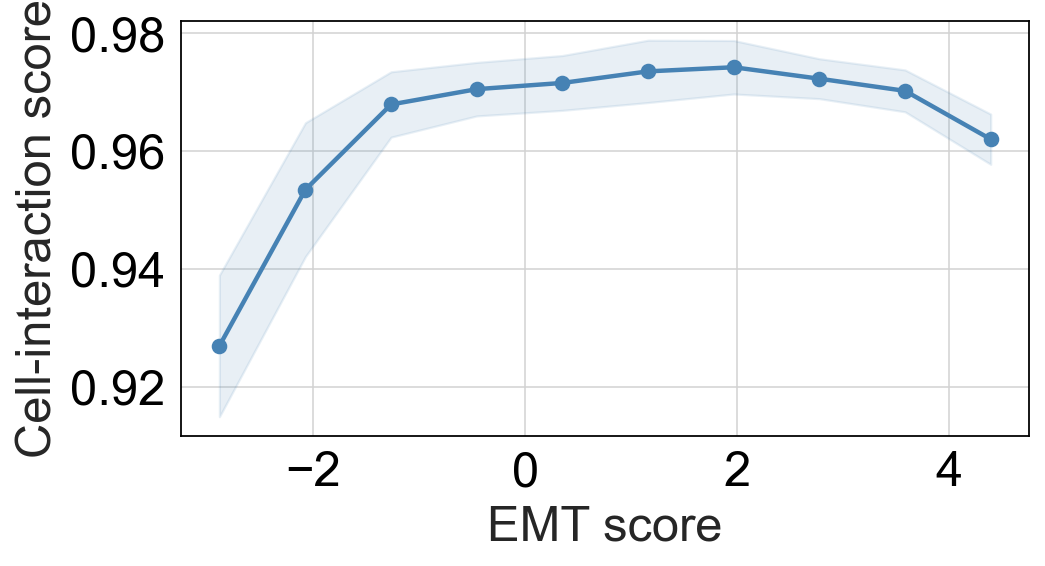

In [16]:
obs = adata_combined.obs.copy()
obs["emt_bin"] = pd.cut(obs["76GS_EMT_score"], bins=10)

grouped = obs.groupby("emt_bin", observed=True)[cell_score]
mean_cell_score = grouped.mean()
std_cell_score = grouped.std()
bin_centers = [interval.mid for interval in mean_cell_score.index]

fig, ax = plt.subplots(figsize=(7, 4), facecolor="white")
ax.set_facecolor("white")
ax.grid(True, color="lightgray", linewidth=0.7)
ax.plot(bin_centers, mean_cell_score.values, marker="o", color="steelblue", linewidth=2)
ax.fill_between(bin_centers, mean_cell_score.values - std_cell_score.values,
                 mean_cell_score.values + std_cell_score.values, alpha=0.12, color="steelblue")
ax.set_xlabel("EMT score")
ax.set_ylabel(f"Cell-interaction score")
fig.tight_layout()
fig.savefig(f"{outdir}/mean_cell_score_by_emt_bin.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:


adata_combined.obs["cell_score_bin"] = pd.cut(
adata_combined.obs[cell_score],
bins=10
)


P_ct_given_s_bin1 = pd.crosstab(
adata_combined.obs["cell_score_bin"],
adata_combined.obs["phase"],
normalize="index"
)
fig, ax = plt.subplots(figsize=(8, 4))

P_ct_given_s_bin1.plot(kind="bar", stacked=True, ax=ax)

ax.legend(
    title="Phase",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=14,
    title_fontsize=16,
    frameon=False
)


ax.set_xticklabels(
    [f"{i + 1}" for i in range(len(P_ct_given_s_bin1.index))],
    rotation=45
)

ax.set_xlabel("Cell-interaction score bin")
ax.set_ylabel("P(Phase)")
ax.set_title(f"P(Phase | cell-interaction score)")



plt.tight_layout()
crisp.save_plot(f"{outdir}/phase_dist_vs_{cell_score}.png")
 # change these



In [44]:
adata_combined.obs["cell_score_bin2"] = pd.qcut(
        adata_combined.obs[cell_score],
        q=10,
        duplicates="drop"   # important if values repeat
    )
P_ct_given_s_bin2 = pd.crosstab(
adata_combined.obs["cell_score_bin2"],
adata_combined.obs["phase"],
normalize="index"
)
fig, ax = plt.subplots(figsize=(8, 4), facecolor="white")
ax.set_facecolor("white")

P_ct_given_s_bin2.plot(kind="bar", stacked=True, ax=ax)

ax.grid(True, axis="both", color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(True)
ax.legend(
    title="Cell Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=14,
    title_fontsize=16,
    frameon=False
)

ax.set_xticklabels(
    [f"{i + 1}" for i in range(len(P_ct_given_s_bin2.index))],
    rotation=0
)

ax.set_xlabel("Cell-interaction score bin")
ax.set_ylabel("P(Cell Type)")
ax.set_title("P(Cell Type | cell-interaction score)")

plt.tight_layout()
crisp.save_plot(f"{outdir}/phase_dist_vs_{cell_score}_qcut.png")

EMT-CC interaction


In [19]:
# encode phase as circular signal
import scanpy as sc
outdir = "../EMT-CC_figures_pearson_rbf"
os.makedirs(outdir, exist_ok=True)
sc.settings.figdir = outdir
sc.settings.set_figure_params(facecolor="white", fontsize=22)

# encode dose_pM as ordered categorical with a "cool" gradient palette
import matplotlib.cm as cm
import matplotlib.colors as mcolors
adata_combined_for_CC_EMT = adata_combined.copy()

doses_ordered = sorted(adata_combined_for_CC_EMT.obs["dose_pM"].dropna().unique())
dose_labels = [str(int(d)) if d == int(d) else str(d) for d in doses_ordered]
adata_combined_for_CC_EMT.obs["dose_pM_cat"] = (
    adata_combined_for_CC_EMT.obs["dose_pM"]
    .map(dict(zip(doses_ordered, dose_labels)))
    .astype("category")
)
adata_combined_for_CC_EMT.obs["dose_pM_cat"] = adata_combined_for_CC_EMT.obs["dose_pM_cat"].cat.set_categories(
    dose_labels, ordered=True
)
_cmap_cool = cm.get_cmap("cool", len(doses_ordered))
adata_combined_for_CC_EMT.uns["dose_pM_cat_colors"] = [
    mcolors.to_hex(_cmap_cool(i / max(len(doses_ordered) - 1, 1))) for i in range(len(doses_ordered))
]

# encode phase as circular signal
crisp.encode_obs(adata_combined_for_CC_EMT, "76GS_EMT_score")
crisp.encode_circular(adata_combined_for_CC_EMT, "phase")



/tmp/ipykernel_3960789/2753645499.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_cool = cm.get_cmap("cool", len(doses_ordered))


'circular_phase'

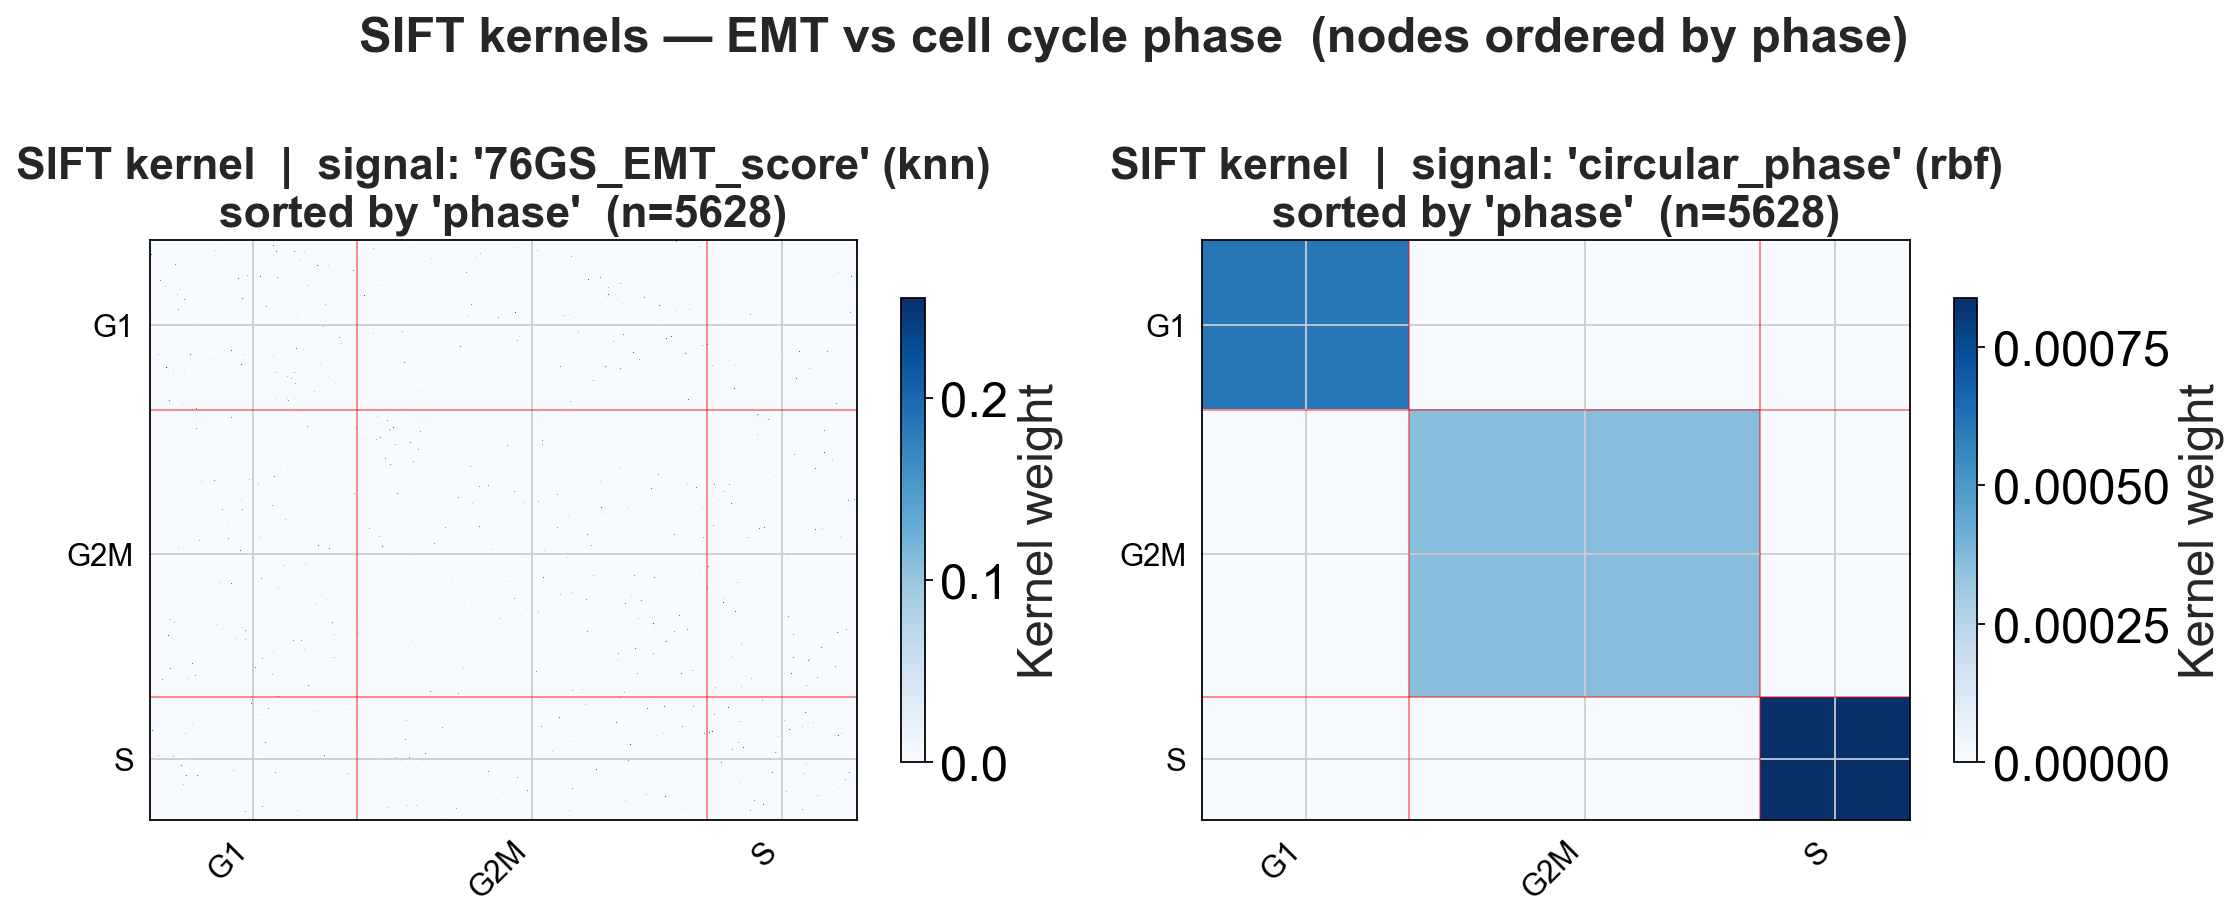

In [20]:
# Setting 2: EMT vs cell cycle phase — kernels sorted by phase
_outdir2 = "../EMT-CC_figures_pearson_rbf"
os.makedirs(_outdir2, exist_ok=True)
LENGTH_SCALE_B = 0.0001
_kp = {"length_scale": LENGTH_SCALE_B} if LENGTH_SCALE_B is not None else None
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_sift_kernel(
    adata_combined_for_CC_EMT,
    signal_key="76GS_EMT_score",
    groupby="phase",
    metric="knn",
    ax=axes[0],
)
plot_sift_kernel(
    adata_combined_for_CC_EMT,
    signal_key="circular_phase",
    groupby="phase",
    metric="rbf",
    kernel_params=_kp,
    ax=axes[1],
)
plt.suptitle("SIFT kernels — EMT vs cell cycle phase  (nodes ordered by phase)", fontsize=22)
plt.tight_layout()
plt.savefig(os.path.join(_outdir2, "kernels_emt_vs_phase.png"), bbox_inches="tight", dpi=150)
plt.show()

[timing] PCA + neighbors:   4.23s
[timing] SIFT signal A:     1.01s
0.0001
[timing] SIFT signal B:     153.88s


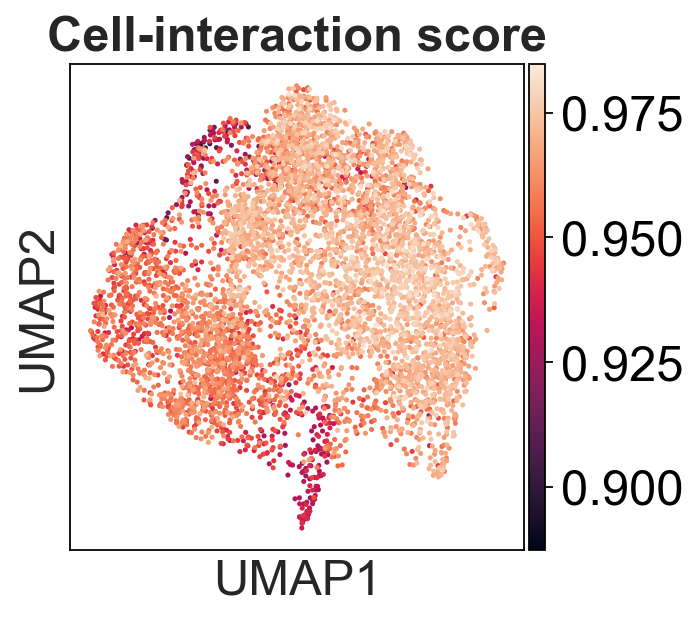

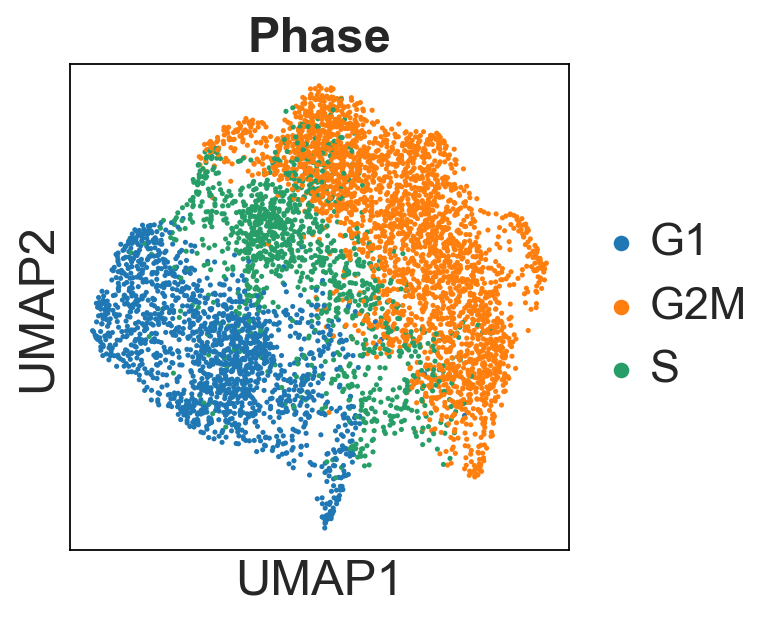

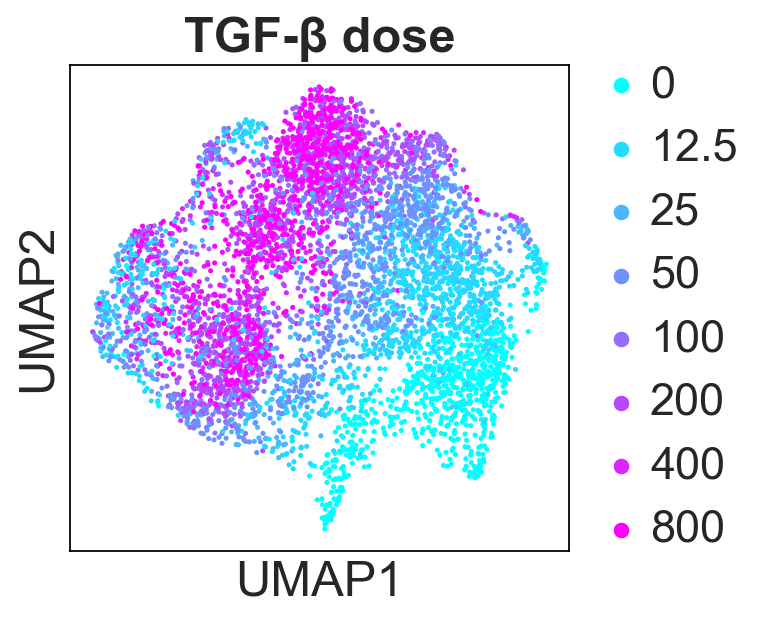

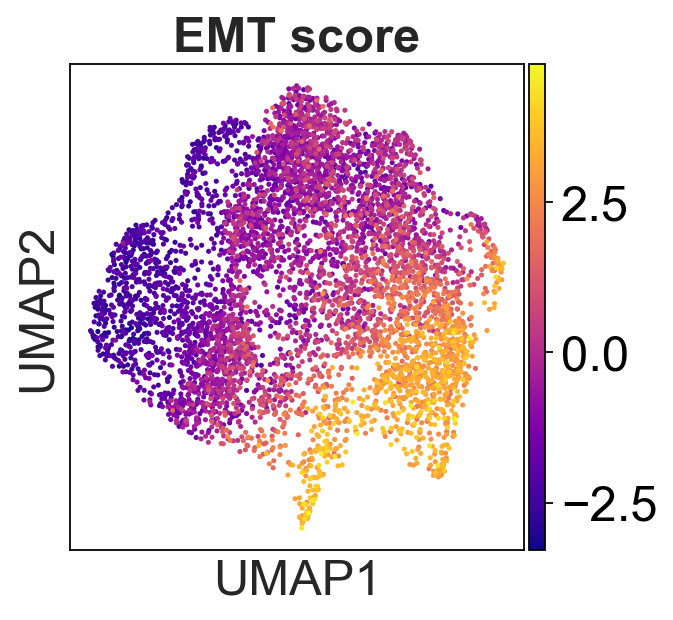

In [21]:
LENGTH_SCALE_B = 0.0001  # set to a float to override the median heuristic for circular_phase

global_score = crisp.compute_projection_similarity(
    adata_combined_for_CC_EMT,
    signal_A="76GS_EMT_score",
    signal_B="circular_phase",
    embedding_key="X",
    metric_A="knn",
    metric_B="rbf",
    device="cuda",
    kernel_params_B={"length_scale": LENGTH_SCALE_B} if LENGTH_SCALE_B is not None else None,
)
sc.settings.set_figure_params(facecolor="white", fontsize=22)
sc.pp.neighbors(adata_combined_for_CC_EMT, n_neighbors=15, use_rep="X_pca")
sc.tl.umap(adata_combined_for_CC_EMT)
cell_score = "proj_pearson_cell"
score = adata_combined_for_CC_EMT.obs[cell_score]
# low_thr = score.quantile(0.025)
# high_thr = score.quantile(0.975)
for _color, _save, _title, _kwargs in [
    (cell_score,       "_emt_cc_cell_score.png", "Cell-interaction score",  {}),
    ("phase",          "_emt_cc_phase.png",       "Phase",       {}),
    ("dose_pM_cat",    "_emt_cc_dose.png",        "TGF-β dose",  {}),
    ("76GS_EMT_score", "_emt_cc_emt_score.png",   "EMT score",   {"color_map": "plasma"}),
]:
    sc.pl.umap(adata_combined_for_CC_EMT, color=[_color], title=[_title], save=_save, **_kwargs)

/tmp/ipykernel_3960789/4170707191.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_cool = cm.get_cmap("cool", _n)


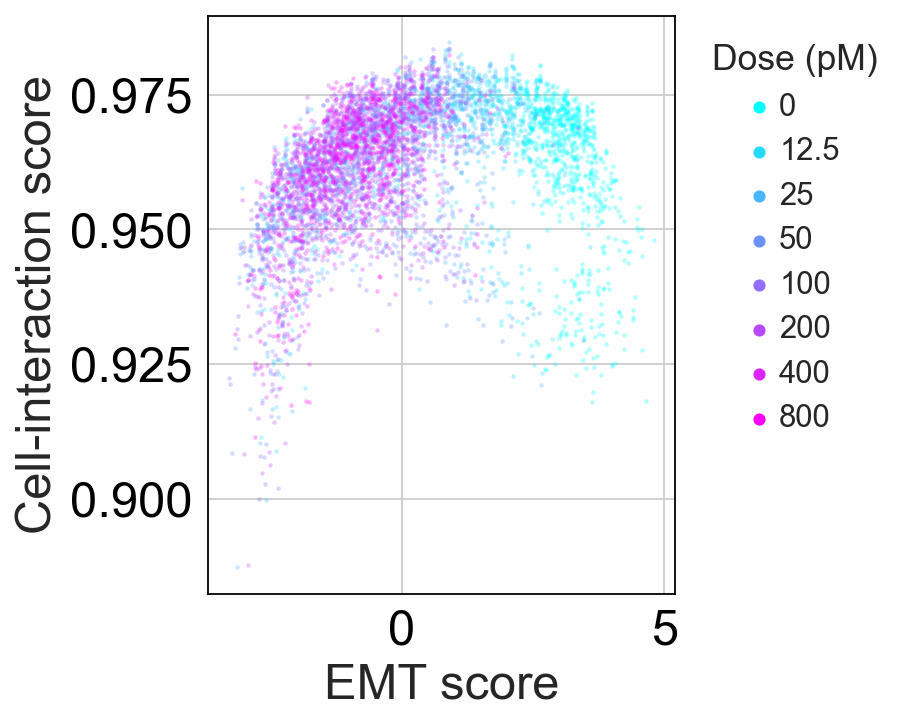

In [22]:
from scipy.stats import spearmanr

x = adata_combined_for_CC_EMT.obs["76GS_EMT_score"]
y = adata_combined_for_CC_EMT.obs[cell_score]
r, p = spearmanr(x, y)

doses = adata_combined_for_CC_EMT.obs["dose_pM_cat"].cat.categories
_n = len(doses)
_cmap_cool = cm.get_cmap("cool", _n)
dose_colors = {d: mcolors.to_hex(_cmap_cool(i / max(_n - 1, 1))) for i, d in enumerate(doses)}

fig, ax = plt.subplots(figsize=(6, 5))
for dose in doses:
    mask = adata_combined_for_CC_EMT.obs["dose_pM_cat"] == dose
    ax.scatter(x[mask], y[mask], color=dose_colors[dose],
               s=4, alpha=0.3, linewidths=0, rasterized=True, label=dose)

handles = [plt.scatter([], [], color=dose_colors[d], s=20, label=d) for d in doses]
ax.legend(handles=handles, title="Dose (pM)", bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=14, title_fontsize=16, frameon=False)
ax.set_xlabel("EMT score")
ax.set_ylabel("Cell-interaction score")
# ax.set_title(f"Cell-interaction score  EMT score")

plt.tight_layout()
fig.savefig(os.path.join(outdir, "spearman_cell_vs_emt_score_by_dose9.png"), dpi=300, bbox_inches="tight")
plt.show()

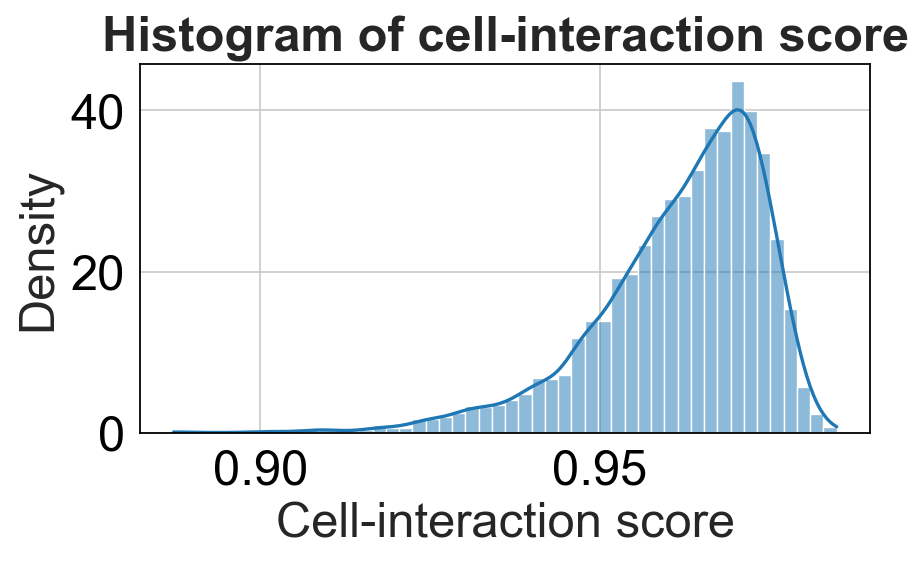

/tmp/ipykernel_3960789/2326597517.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_bar = cm.get_cmap("viridis", _n)


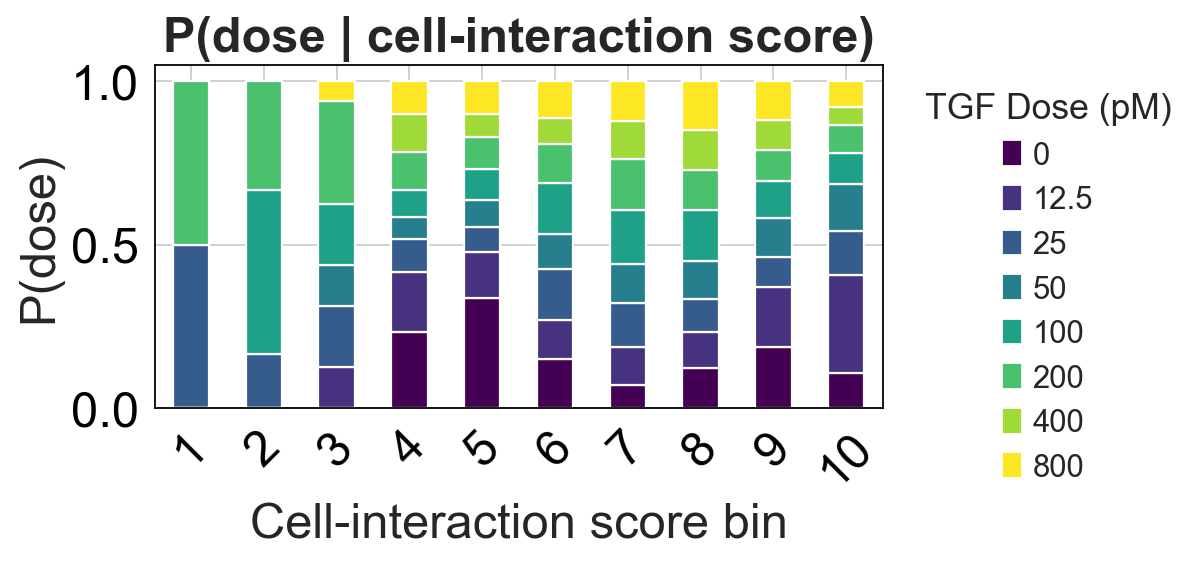

In [23]:
import seaborn as sns
# mask = (score >= low_thr) & (score <= high_thr)
# adata_filt = adata_combined_for_CC_EMT[mask].copy()
# scored_filt = score[mask].copy()
fig_hist, ax_hist = plt.subplots(figsize=(6, 4))
sns.histplot(score, bins=50, stat="density", kde=True, ax=ax_hist)

ax_hist.set_xlabel("Cell-interaction score")
ax_hist.set_ylabel("Density")
ax_hist.set_title(f"Histogram of cell-interaction score")

fig_hist.tight_layout()
fig_hist.savefig(os.path.join(outdir, "cell_score_histogram_cc.png"), dpi=300, bbox_inches="tight")
plt.show()


adata_combined_for_CC_EMT.obs["cell_score_bin"] = pd.cut(
    adata_combined_for_CC_EMT.obs[cell_score],
    bins=10
)


P_ct_given_s_bin1 = pd.crosstab(
    adata_combined_for_CC_EMT.obs["cell_score_bin"],
    adata_combined_for_CC_EMT.obs["dose_pM"],
    normalize="index"
)

# continuous viridis colors mapped to doses
_doses_all = sorted(adata_combined_for_CC_EMT.obs["dose_pM"].dropna().unique())
_n = len(_doses_all)
_cmap_bar = cm.get_cmap("viridis", _n)
_dose_to_color = {d: _cmap_bar(i / max(_n - 1, 1)) for i, d in enumerate(_doses_all)}
_bar_colors = [_dose_to_color[d] for d in P_ct_given_s_bin1.columns]

fig, ax = plt.subplots(figsize=(8, 4))
P_ct_given_s_bin1.plot(kind="bar", stacked=True, ax=ax, color=_bar_colors)

handles = [plt.Rectangle((0, 0), 1, 1, color=_dose_to_color[d]) for d in P_ct_given_s_bin1.columns]
labels = [str(int(d)) if d == int(d) else str(d) for d in P_ct_given_s_bin1.columns]
ax.legend(
    handles, labels,
    title="TGF Dose (pM)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=14,
    title_fontsize=16,
    frameon=False
)

ax.set_xticklabels(
    [f"{i + 1}" for i in range(len(P_ct_given_s_bin1.index))],
    rotation=0
)
ax.set_xlabel("Cell-interaction score bin")
ax.set_ylabel("P(dose)")
# ax.set_title(f"P(dose | cell-interaction score)")

plt.tight_layout()
fig.savefig(os.path.join(outdir, "dose_dist_vs_cell_score_cc.png"), dpi=300, bbox_inches="tight")

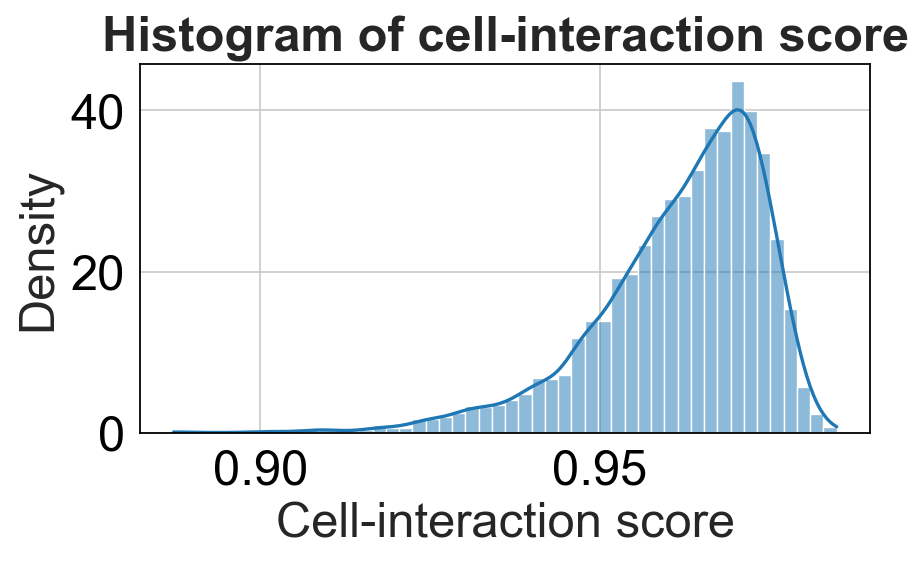

/tmp/ipykernel_3960789/1824196791.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  _cmap_bar = cm.get_cmap("cool", _n)


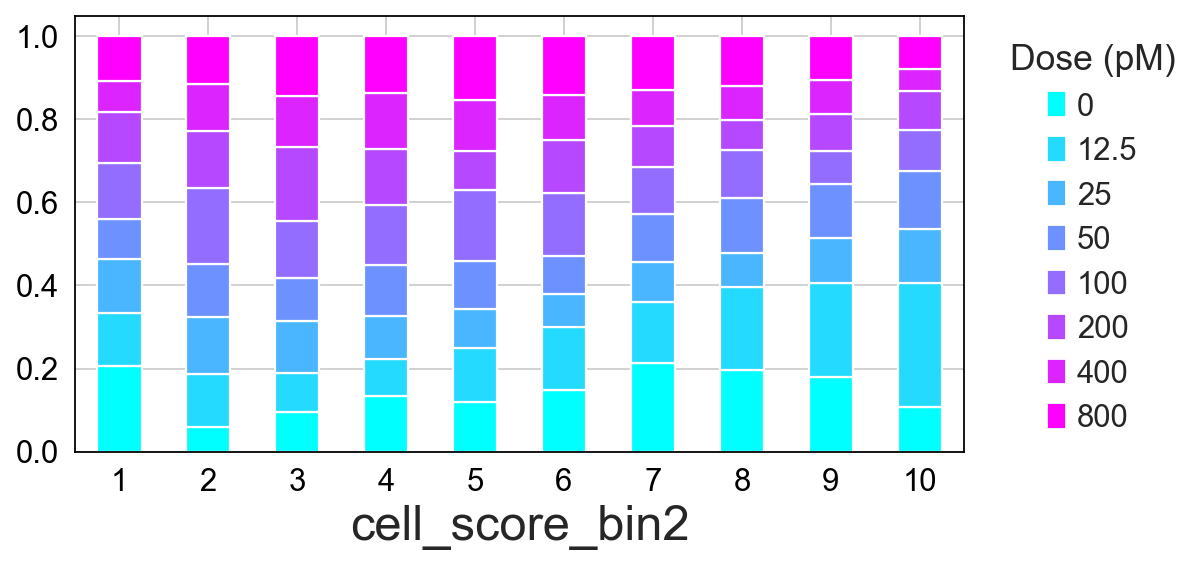

In [33]:
import seaborn as sns
# mask = (score >= low_thr) & (score <= high_thr)
# adata_filt = adata_combined[mask].copy()
# scored_filt = score[mask].copy()
fig_hist, ax_hist = plt.subplots(figsize=(6, 4))
sns.histplot(score, bins=50, stat="density", kde=True, ax=ax_hist)

ax_hist.set_xlabel("Cell-interaction score")
ax_hist.set_ylabel("Density")
ax_hist.set_title(f"Histogram of cell-interaction score")

fig_hist.tight_layout()
fig_hist.savefig(os.path.join(outdir, "cell_score_histogram_cc_qcut.png"), dpi=300, bbox_inches="tight")
plt.show()


adata_combined_for_CC_EMT.obs["cell_score_bin2"] = pd.qcut(
    adata_combined_for_CC_EMT.obs[cell_score],
    q=10,
    duplicates="drop"
)

P_ct_given_s_bin2 = pd.crosstab(
    adata_combined_for_CC_EMT.obs["cell_score_bin2"],
    adata_combined_for_CC_EMT.obs["dose_pM"],
    normalize="index"
)

# continuous viridis colors mapped to doses
_doses_all = sorted(adata_combined_for_CC_EMT.obs["dose_pM"].dropna().unique())
_n = len(_doses_all)
_cmap_bar = cm.get_cmap("cool", _n)
_dose_to_color = {d: _cmap_bar(i / max(_n - 1, 1)) for i, d in enumerate(_doses_all)}
_bar_colors = [_dose_to_color[d] for d in P_ct_given_s_bin2.columns]

fig, ax = plt.subplots(figsize=(8, 4))
P_ct_given_s_bin2.plot(kind="bar", stacked=True, ax=ax, color=_bar_colors)

handles = [plt.Rectangle((0, 0), 1, 1, color=_dose_to_color[d]) for d in P_ct_given_s_bin2.columns]
labels = [str(int(d)) if d == int(d) else str(d) for d in P_ct_given_s_bin2.columns]
ax.legend(
    handles, labels,
    title="Dose (pM)",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=14,
    title_fontsize=16,
    frameon=False
)
ax.tick_params(axis="both", labelsize=14)
ax.set_xticklabels(
    [f"{i + 1}" for i in range(len(P_ct_given_s_bin2.index))],
    rotation=0
)
# ax.set_xlabel("Cell-interaction score bin")
# ax.set_ylabel("P(dose)")
# ax.set_title(f"P(dose | cell-interaction score)")

plt.tight_layout()
fig.savefig(os.path.join(outdir, "dose_dist_vs_cell_score_cc_qcut.png"), dpi=300, bbox_inches="tight")

In [28]:
doses = sorted(adata_combined_for_CC_EMT.obs["dose_pM"].unique())
cmap = plt.cm.get_cmap("cool", len(doses))
dose_colors = {d: cmap(i) for i, d in enumerate(doses)}

for label, phases, fname in [("G1", ["G1"], "scatter_EMT_cellscore_G1.png"),
                            ("G2M / S", ["G2M", "S"], "scatter_EMT_cellscore_G2M_S.png")]:
  mask = adata_combined_for_CC_EMT.obs["phase"].isin(phases)
  sub = adata_combined_for_CC_EMT.obs[mask]

  fig, ax = plt.subplots(figsize=(6, 5))
  for dose, grp in sub.groupby("dose_pM"):
      ax.scatter(
          grp["76GS_EMT_score"],
          grp[cell_score],
          c=[dose_colors[dose]],
          s=8,
          alpha=0.7,
          label=str(dose),
      )
  ax.set_xlabel("EMT score")
  ax.set_ylabel("Cell-interaction score")
  ax.set_title(f"{label} cells")
  # ax.legend(title="Dose (pM)", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
  plt.tight_layout()
  plt.savefig(os.path.join(outdir, fname), dpi=150, bbox_inches="tight")
  plt.show()


KeyboardInterrupt: 